<a href="https://colab.research.google.com/github/Wahyudi-Satriawan/244107020137_TI3H_PembelajaranMesin/blob/main/JS11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

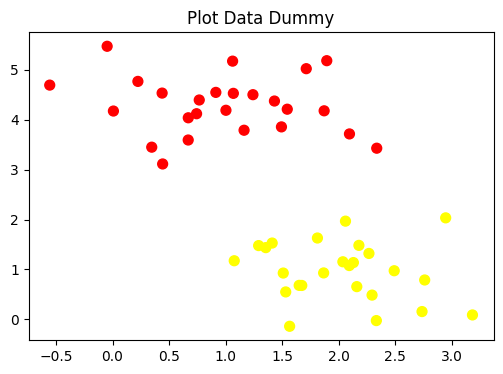

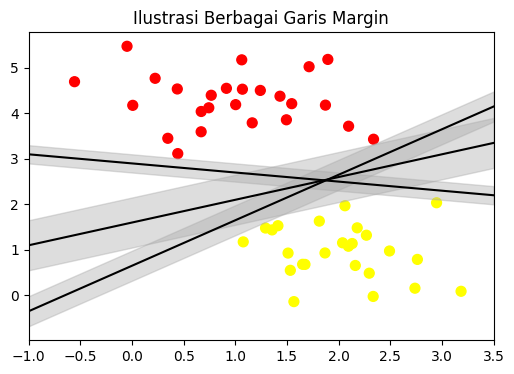

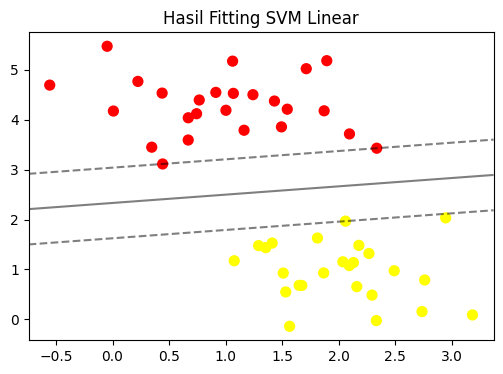

Titik Support Vectors:
[[0.44359863 3.11530945]
 [2.33812285 3.43116792]
 [2.06156753 1.96918596]]
------------------------------


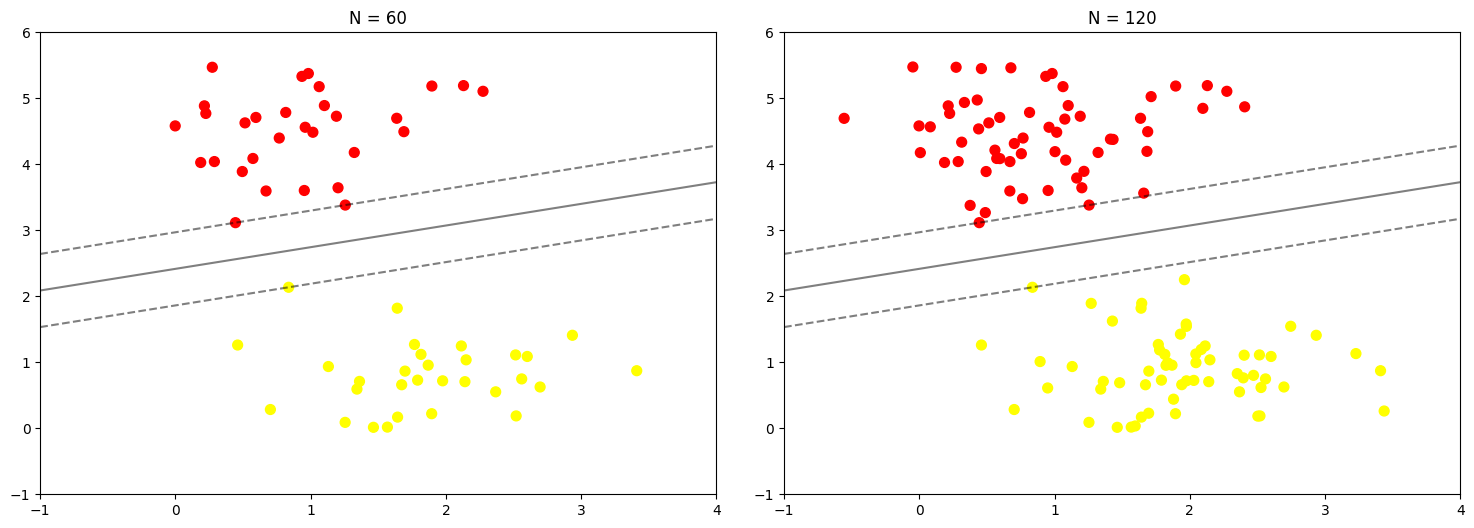

Widget Interaktif SVM:


interactive(children=(Dropdown(description='N', options=(10, 200), value=10), Output()), _dom_classes=('widget…

<function __main__.plot_svm(N=10, ax=None)>

In [6]:
# Praktikum 1: Klasifikasi SVM dengan Data Dummy Linier

# Langkah 1 - Import Library
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.svm import SVC
from ipywidgets import interact, fixed

# Langkah 2 - Membuat Data Dummy
X, y = make_blobs(n_samples=50, centers=2, random_state=0, cluster_std=0.60)

plt.figure(figsize=(6, 4))
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plt.title("Plot Data Dummy")
plt.show()

# Langkah 3 & 4 - Ilustrasi Margin
xfit = np.linspace(-1, 3.5)
plt.figure(figsize=(6, 4))
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

# Membuat 3 garis uji coba dengan marginnya
for m, b, d in [(1, 0.65, 0.33), (0.5, 1.6, 0.55), (-0.2, 2.9, 0.2)]:
    yfit = m * xfit + b
    plt.plot(xfit, yfit, '-k')
    plt.fill_between(xfit, yfit - d, yfit + d, edgecolor='none', color='#AAAAAA', alpha=0.4)

plt.xlim(-1, 3.5)
plt.title("Ilustrasi Berbagai Garis Margin")
plt.show()

# Langkah 5 - Fitting Model SVM Linear
model = SVC(kernel='linear', C=1E10)
model.fit(X, y)

# Fungsi untuk memvisualisasikan model (batas dan margin)
def plot_svc_decision_function(model, ax=None, plot_support=True):
    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # Buat grid untuk evaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X_mesh = np.meshgrid(y, x)
    xy = np.vstack([X_mesh.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X_mesh.shape)

    # Plot batas dan margin
    ax.contour(X_mesh, Y, P, colors='k', levels=[-1, 0, 1], alpha=0.5, linestyles=['--', '-', '--'])

    # Plot titik support vectors
    if plot_support:
        ax.scatter(model.support_vectors_[:, 0], model.support_vectors_[:, 1],
                   s=300, linewidth=1, facecolors='none')
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

# Menampilkan hasil fitting
plt.figure(figsize=(6, 4))
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(model)
plt.title("Hasil Fitting SVM Linear")
plt.show()

print("Titik Support Vectors:")
print(model.support_vectors_)
print("-" * 30)

# Perbandingan model dengan data awal 60 dan 120
def plot_svm(N=10, ax=None):
    X_new, y_new = make_blobs(n_samples=200, centers=2, random_state=0, cluster_std=0.60)
    X_new = X_new[:N]
    y_new = y_new[:N]
    model_new = SVC(kernel='linear', C=1E10)
    model_new.fit(X_new, y_new)

    ax = ax or plt.gca()
    ax.scatter(X_new[:, 0], X_new[:, 1], c=y_new, s=50, cmap='autumn')
    ax.set_xlim(-1, 4)
    ax.set_ylim(-1, 6)
    plot_svc_decision_function(model_new, ax)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)
for axi, N in zip(ax, [60, 120]):
    plot_svm(N, axi)
    axi.set_title(f'N = {N}')
plt.show()

# Interaksi jumlah data (opsional, jika ipywidgets berjalan di Colab)
print("Widget Interaktif SVM:")
interact(plot_svm, N=[10, 200], ax=fixed(None))

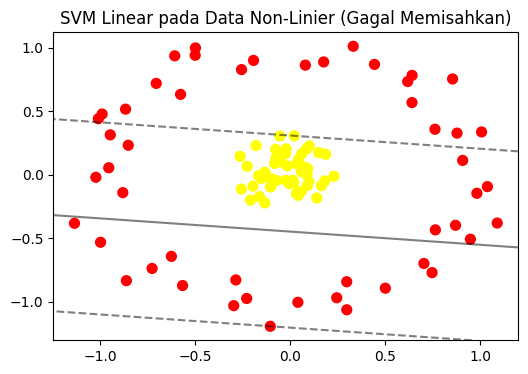

Widget Interaktif Plot 3D:


interactive(children=(Dropdown(description='elev', index=2, options=(-90, 45, 30, 20, 10), value=30), IntSlide…

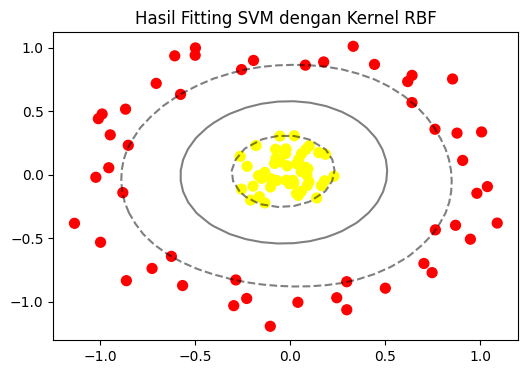

In [7]:
# Praktikum 2: Klasifikasi SVM dengan Data Dummy Non-Linier

# Langkah 1a - Import Library
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_circles
from sklearn.svm import SVC
from mpl_toolkits.mplot3d import Axes3D
from ipywidgets import interact, fixed

# Langkah 1b - Buat Kembali Fungsi Plotting (Agar mandiri 1 sel)
def plot_svc_decision_function(model, ax=None, plot_support=True):
    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X_mesh = np.meshgrid(y, x)
    xy = np.vstack([X_mesh.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X_mesh.shape)

    ax.contour(X_mesh, Y, P, colors='k', levels=[-1, 0, 1], alpha=0.5, linestyles=['--', '-', '--'])

    if plot_support:
        ax.scatter(model.support_vectors_[:, 0], model.support_vectors_[:, 1],
                   s=300, linewidth=1, facecolors='none')
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

# Langkah 1c - Buat Data Dummy Non-Linier (Lingkaran)
X, y = make_circles(100, factor=.1, noise=.1)

# Uji coba dengan SVM Linear (akan gagal memisahkan secara jelas)
clf_linear = SVC(kernel='linear').fit(X, y)

plt.figure(figsize=(6, 4))
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(clf_linear, plot_support=False)
plt.title("SVM Linear pada Data Non-Linier (Gagal Memisahkan)")
plt.show()

# Proyeksi basis radial untuk 3D
r = np.exp(-(X ** 2).sum(1))

# Fungsi plot 3D dengan interaksi
def plot_3D(elev=30, azim=30, X_data=X, y_data=y):
    fig = plt.figure(figsize=(8, 6))
    ax = fig.add_subplot(111, projection='3d')
    ax.scatter(X_data[:, 0], X_data[:, 1], r, c=y_data, s=50, cmap='autumn')
    ax.view_init(elev=elev, azim=azim)
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_zlabel('r')
    plt.title("Proyeksi Radial 3D")
    plt.show()

# Menampilkan plot 3D Interaktif
print("Widget Interaktif Plot 3D:")
interact(plot_3D, elev=[-90, 45, 30, 20, 10], azim=(-180, 180), X_data=fixed(X), y_data=fixed(y))

# Langkah 2 - Fitting Model dengan Kernel RBF
clf_rbf = SVC(kernel='rbf', C=1E6)
clf_rbf.fit(X, y)

plt.figure(figsize=(6, 4))
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plot_svc_decision_function(clf_rbf)
plt.scatter(clf_rbf.support_vectors_[:, 0], clf_rbf.support_vectors_[:, 1],
            s=300, lw=1, facecolors='none')
plt.title("Hasil Fitting SVM dengan Kernel RBF")
plt.show()

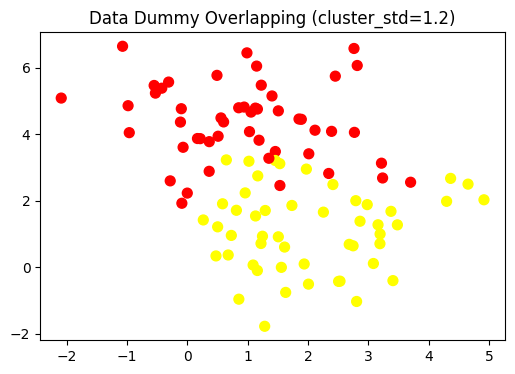

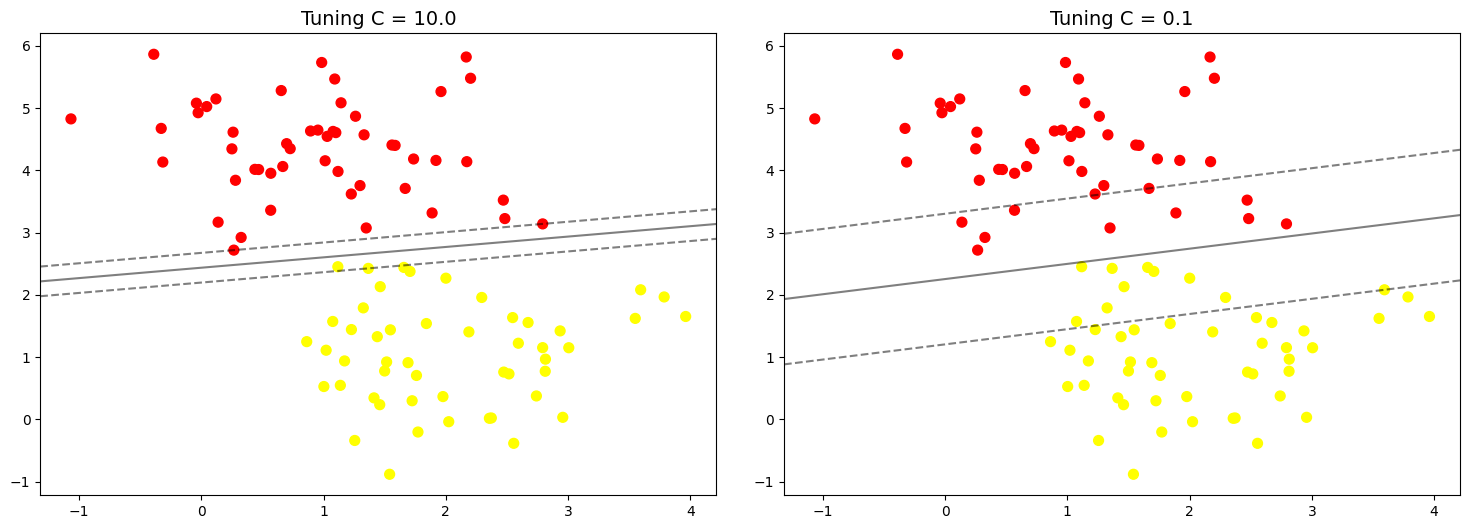

In [8]:
# Praktikum 3: SVM Data Overlapping

# Langkah 1 - Import Library & Fungsi Plotting
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.svm import SVC

def plot_svc_decision_function(model, ax=None, plot_support=True):
    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X_mesh = np.meshgrid(y, x)
    xy = np.vstack([X_mesh.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X_mesh.shape)

    ax.contour(X_mesh, Y, P, colors='k', levels=[-1, 0, 1], alpha=0.5, linestyles=['--', '-', '--'])

    if plot_support:
        ax.scatter(model.support_vectors_[:, 0], model.support_vectors_[:, 1],
                   s=300, linewidth=1, facecolors='none')
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

# Langkah 2 - Buat Data Dummy Tumpang Tindih
# std deviasi dibesarkan (1.2) agar data menyebar dan menumpuk
X, y = make_blobs(n_samples=100, centers=2, random_state=0, cluster_std=1.2)

plt.figure(figsize=(6, 4))
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
plt.title("Data Dummy Overlapping (cluster_std=1.2)")
plt.show()

# Langkah 3 - Analisis Dampak Tuning Parameter C
# Mengurangi sedikit std ke 0.8 untuk melihat dampak C lebih jelas
X_tune, y_tune = make_blobs(n_samples=100, centers=2, random_state=0, cluster_std=0.8)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)

# Mencoba dua nilai C berbeda: 10.0 (Hard Margin) vs 0.1 (Soft Margin)
for axi, C in zip(ax, [10.0, 0.1]):
    model_tune = SVC(kernel='linear', C=C).fit(X_tune, y_tune)
    axi.scatter(X_tune[:, 0], X_tune[:, 1], c=y_tune, s=50, cmap='autumn')
    plot_svc_decision_function(model_tune, axi)
    axi.scatter(model_tune.support_vectors_[:, 0], model_tune.support_vectors_[:, 1],
                s=300, lw=1, facecolors='none')
    axi.set_title(f'Tuning C = {C:.1f}', size=14)

plt.show()

Mengunduh dataset wajah (bisa memakan waktu)...
Target names: ['Ariel Sharon' 'Colin Powell' 'Donald Rumsfeld' 'George W Bush'
 'Gerhard Schroeder' 'Hugo Chavez' 'Junichiro Koizumi' 'Tony Blair']
Jumlah target: 8
Shape images: (1348, 62, 47)
----------------------------------------


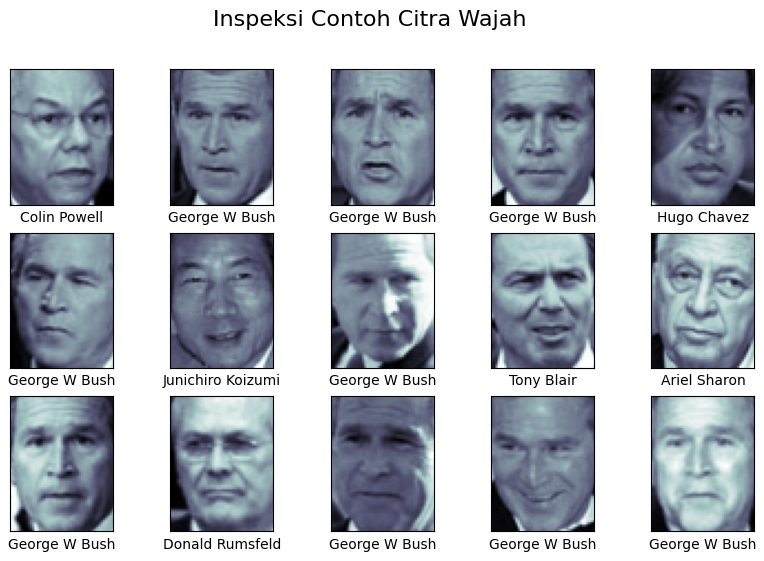

Melakukan GridSearch untuk tuning hyperparameter...


In [ ]:
# Praktikum 4: Klasifikasi Citra Wajah

# Langkah 0 - Import Library dan Unduh Dataset
from sklearn.datasets import fetch_lfw_people
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

print("Mengunduh dataset wajah (bisa memakan waktu)...")
faces = fetch_lfw_people(min_faces_per_person=60)
print("Target names:", faces.target_names)
print("Jumlah target:", len(faces.target_names))
print("Shape images:", faces.images.shape)
print("-" * 40)

# Langkah 1 - Inspeksi Citra Wajah
fig, ax = plt.subplots(3, 5, figsize=(10, 6))
for i, axi in enumerate(ax.flat):
    axi.imshow(faces.images[i], cmap='bone')
    axi.set(xticks=[], yticks=[], xlabel=faces.target_names[faces.target[i]])
plt.suptitle("Inspeksi Contoh Citra Wajah", fontsize=16)
plt.show()

# Langkah 2 & 3 - Pra Pengolahan Data (PCA) dan Split Data
# (Penggunaan svd_solver='randomized' menggantikan fungsi RandomizedPCA yang sudah usang)
pca = PCA(n_components=150, svd_solver='randomized', whiten=True, random_state=42)
svc = SVC(kernel='rbf', class_weight='balanced')
model = make_pipeline(pca, svc)

Xtrain, Xtest, ytrain, ytest = train_test_split(faces.data, faces.target, random_state=42)

# Langkah 4 - Pembuatan Model + Tuning (GridSearchCV)
print("Melakukan GridSearch untuk tuning hyperparameter...")
param_grid = {'svc__C': [1, 5, 10, 50],
              'svc__gamma': [0.0001, 0.0005, 0.001, 0.005]}
grid = GridSearchCV(model, param_grid)
grid.fit(Xtrain, ytrain)

print("Hyperparameter Terbaik:", grid.best_params_)
print("Akurasi GridSearch:", grid.best_score_)
print("-" * 40)

# Prediksi menggunakan model terbaik hasil GridSearch
model_best = grid.best_estimator_
yfit = model_best.predict(Xtest)

# Langkah 5 - Cek Hasil Prediksi Visual
fig, ax = plt.subplots(4, 6, figsize=(10, 8))
for i, axi in enumerate(ax.flat):
    axi.imshow(Xtest[i].reshape(62, 47), cmap='bone')
    axi.set(xticks=[], yticks=[])
    # Label warna merah jika prediksi salah
    axi.set_ylabel(faces.target_names[yfit[i]].split()[-1],
                   color='black' if yfit[i] == ytest[i] else 'red')
fig.suptitle('Prediksi Nama (Label Salah berwarna Merah)', size=14)
plt.show()

# Langkah 6 - Cek Performansi (Classification Report & Confusion Matrix)
print("\nClassification Report:\n")
print(classification_report(ytest, yfit, target_names=faces.target_names))

mat = confusion_matrix(ytest, yfit)
plt.figure(figsize=(8, 6))
sns.heatmap(mat.T, square=True, annot=True, fmt='d', cbar=False,
            xticklabels=faces.target_names, yticklabels=faces.target_names)
plt.xlabel('True Label (Label Asli)')
plt.ylabel('Predicted Label (Label Prediksi)')
plt.title('Confusion Matrix')
plt.show()

In [ ]:
# Praktikum 5: Klasifikasi Citra Siang dan Malam

# Langkah 0 - Import Library
from pathlib import Path
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import cv2
import numpy as np
import pandas as pd
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Direktori Gambar
# (Pastikan folder 'images' sudah terupload di Google Colab)
train_dir = "images/training/"
test_dir = "images/test/"

# Langkah 1 & 2 - Fungsi Load Data dan Visualisasi
def load_dataset(img_dir):
    p = Path(img_dir)
    dirs = p.glob('*')
    img_list = []
    for dir_path in dirs:
        label = str(dir_path).split('/')[-1]
        for file in dir_path.glob('*.jpg'):
            img = mpimg.imread(str(file))
            if img is not None:
                img_list.append((img, label))
    return img_list

def random_img_viz(img_list):
    rand_num = np.random.randint(0, len(img_list))
    img = img_list[rand_num][0]
    label = img_list[rand_num][1]

    plt.figure(figsize=(6, 4))
    plt.imshow(img)
    plt.title(f'Visualisasi Acak - Label: {label} | Shape: {img.shape}')
    plt.show()

print("Memuat dataset training...")
train_img = load_dataset(train_dir)
if len(train_img) == 0:
    print("WARNING: Dataset kosong! Pastikan folder 'images/training/' sudah diupload.")
else:
    random_img_viz(train_img)

# Langkah 3 - Pra Pengolahan Data (Resize & Label Encoding)
def standarized_input(image):
    return cv2.resize(image, (1100, 600))

def label_encoder(label):
    return 1 if label == 'day' else 0

def preprocess(img_list):
    std_img_list = []
    for item in img_list:
        std_img = standarized_input(item[0])
        img_label = label_encoder(item[1])
        std_img_list.append((std_img, img_label))
    return std_img_list

train_std_img_list = preprocess(train_img)

# Langkah 4 - Ekstraksi Fitur (Rata-rata Brightness via HSV)
def avg_brightness(image):
    img_hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)
    sum_brightness = np.sum(img_hsv[:,:,2])
    area = image.shape[0] * image.shape[1]
    return sum_brightness / area

# Langkah 5 & 6 - Klasifikasi Threshold (Manual) & Evaluasi
def predict_label(img, threshold):
    avg = avg_brightness(img)
    return 1 if avg > threshold else 0

def evaluate(img_list, threshold):
    miss_labels = []
    for file in img_list:
        pred_label = predict_label(file[0], threshold)
        if pred_label != file[1]:
            miss_labels.append((file[0], pred_label, file[1]))

    total_img = len(img_list)
    if total_img > 0:
        accuracy = (total_img - len(miss_labels)) / total_img
        print(f'Akurasi Manual (Threshold {threshold}): {accuracy:.4f}')

if len(train_img) > 0:
    print("\n--- Evaluasi Klasifikasi Manual (Threshold) ---")
    print("Data Training:", end=" ")
    evaluate(train_std_img_list, threshold=120)

    test_img = load_dataset(test_dir)
    test_std_img_list = preprocess(test_img)
    print("Data Testing: ", end=" ")
    evaluate(test_std_img_list, threshold=120)

# Langkah Alternatif - Klasifikasi dengan SVM
def extract_avg_bright_feature(img_list):
    avg_list = []
    labels = []
    for img in img_list:
        avg_list.append(avg_brightness(img[0]))
        labels.append(img[1])

    data = np.column_stack((avg_list, labels))
    return pd.DataFrame(data, columns=['AVG_BRIGHT', 'LABELS'])

if len(train_img) > 0:
    print("\n--- Evaluasi Klasifikasi Model SVM ---")
    train_avg_img = extract_avg_bright_feature(train_std_img_list)
    test_avg_img = extract_avg_bright_feature(test_std_img_list)

    # Bentuk format matriks data untuk SVM
    # (astype(int) agar label tidak terbaca sebagai float)
    X_train = train_avg_img.iloc[:,0].values.reshape(-1,1)
    y_train = train_avg_img.iloc[:,1].astype(int)
    X_test = test_avg_img.iloc[:,0].values.reshape(-1,1)
    y_test = test_avg_img.iloc[:,1].astype(int)

    # Training model SVM
    model_svm = SVC()
    model_svm.fit(X_train, y_train)

    # Prediksi & Hitung Akurasi SVM
    acc_train = accuracy_score(y_train, model_svm.predict(X_train))
    acc_test = accuracy_score(y_test, model_svm.predict(X_test))

    print(f'Akurasi SVM pada Train: {acc_train:.4f}')
    print(f'Akurasi SVM pada Test: {acc_test:.4f}')

In [ ]:
# Tugas 1: Klasifikasi SVM dataset voice.csv (Linear, Poly, RBF dengan Rasio 70:30 & 80:20)

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# 1. Load Data
# Pastikan file 'voice.csv' sudah diupload ke Google Colab
try:
    df = pd.read_csv('voice.csv')
except FileNotFoundError:
    print("Error: File 'voice.csv' tidak ditemukan. Silakan upload terlebih dahulu.")
    df = None

if df is not None:
    # 2. Pra-pemrosesan Data
    X = df.drop('label', axis=1) # Pisahkan fitur
    y = LabelEncoder().fit_transform(df['label']) # Encode label 'male' & 'female' ke 0 & 1

    # Standardisasi data (Sangat penting untuk SVM agar konvergen dan akurat)
    X = StandardScaler().fit_transform(X)

    # 3. Skenario Pemodelan
    results = []
    splits = [('70:30', 0.3), ('80:20', 0.2)]
    kernels = ['linear', 'poly', 'rbf']

    # Looping untuk setiap kombinasi rasio split dan kernel
    for split_name, test_size in splits:
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size, random_state=42)

        for kernel in kernels:
            model = SVC(kernel=kernel)
            model.fit(X_train, y_train)
            acc = accuracy_score(y_test, model.predict(X_test))

            # Simpan hasil
            results.append({
                'Rasio Data': split_name,
                'Kernel': kernel,
                'Akurasi': round(acc, 4)
            })

    # 4. Tabulasi Hasil
    results_df = pd.DataFrame(results)
    print("--- TABULASI PERFORMANSI MODEL SVM (VOICE.CSV) ---")
    print(results_df.to_string(index=False))

In [ ]:
# Tugas 2: Klasifikasi Citra Siang/Malam dengan Fitur Histogram & Tuning SVM RBF

import cv2
import numpy as np
import matplotlib.image as mpimg
from pathlib import Path
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# 1. Fungsi Load dan Gabungkan Dataset
# Menggabungkan folder training dan test untuk displit ulang 80:20
def load_all_datasets(dir_list):
    img_list = []
    for img_dir in dir_list:
        p = Path(img_dir)
        if not p.exists():
            continue

        # Iterasi sub-folder (day / night)
        for d in [folder for folder in p.iterdir() if folder.is_dir()]:
            label = d.name
            for file in d.glob('*.jpg'):
                img = mpimg.imread(str(file))
                if img is not None:
                    img_list.append((img, label))
    return img_list

print("Memuat dataset gambar...")
all_images = load_all_datasets(['images/training/', 'images/test/'])

if len(all_images) == 0:
    print("WARNING: Dataset kosong! Pastikan folder 'images' sudah diupload.")
else:
    print(f"Total {len(all_images)} gambar berhasil dimuat.")

    # 2. Ekstraksi Fitur (Histogram HSV)
    X = []
    y = []

    for img, label in all_images:
        # Konversi ke HSV untuk mendeteksi warna dan kecerahan (Value) dengan lebih baik
        hsv_img = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)

        # Hitung Histogram (8 bin per channel)
        hist = cv2.calcHist([hsv_img], [0, 1, 2], None, [8, 8, 8], [0, 180, 0, 256, 0, 256])
        cv2.normalize(hist, hist) # Normalisasi

        X.append(hist.flatten()) # Jadikan 1D Array agar bisa masuk ke SVM
        y.append(1 if label == 'day' else 0)

    X = np.array(X)
    y = np.array(y)

    # 3. Split Data dengan Rasio 80:20
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    # 4. Hyperparameter Tuning Kernel RBF
    print("Melakukan Hyperparameter Tuning SVM (RBF)...")
    param_grid = {
        'C': [0.1, 1, 10, 100],
        'gamma': ['scale', 'auto', 0.01, 0.1, 1]
    }

    grid = GridSearchCV(SVC(kernel='rbf'), param_grid, cv=5)
    grid.fit(X_train, y_train)

    # 5. Evaluasi Performa
    best_model = grid.best_estimator_
    y_pred = best_model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)

    print("\n--- HASIL KLASIFIKASI SIANG & MALAM (FITUR HISTOGRAM) ---")
    print(f"Rasio Data Split       : 80:20")
    print(f"Hyperparameter Terbaik : {grid.best_params_}")
    print(f"Akurasi Model          : {acc:.4f}")